In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from utils.preprocessing import load_data
from utils.config import *

: 

In [ ]:
def plot(train_series, test_series, col_name):
    plt.figure(figsize=(20,4))
    plt.plot(train_series[col_name], label='Train Set', color='blue')
    plt.plot(test_series[col_name], label='Test Set', color='orange')
    plt.xlabel("Time")
    plt.ylabel(f"{col_name}")
    plt.legend()

In [ ]:
## ======= LOAD DATA =======
train_poblesec, test_poblesec = load_data(POBLESEC_ST)
train_elborn, test_elborn = load_data(ELBORN_ST)
train_lescorts, test_lescorts = load_data(LESCORTS_ST)


===== DownLink and UpLink for elborn station in Spain =====


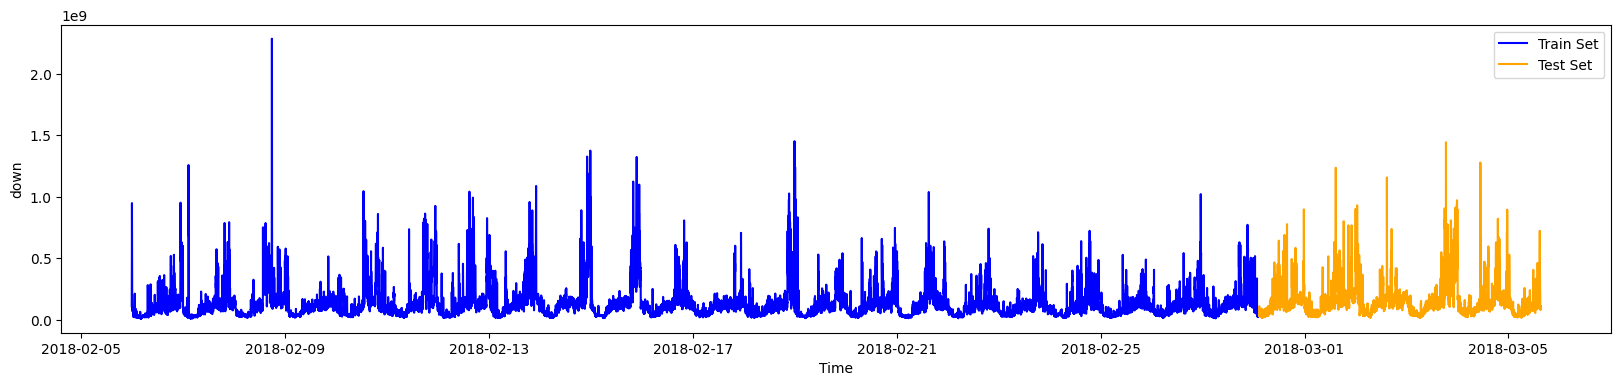

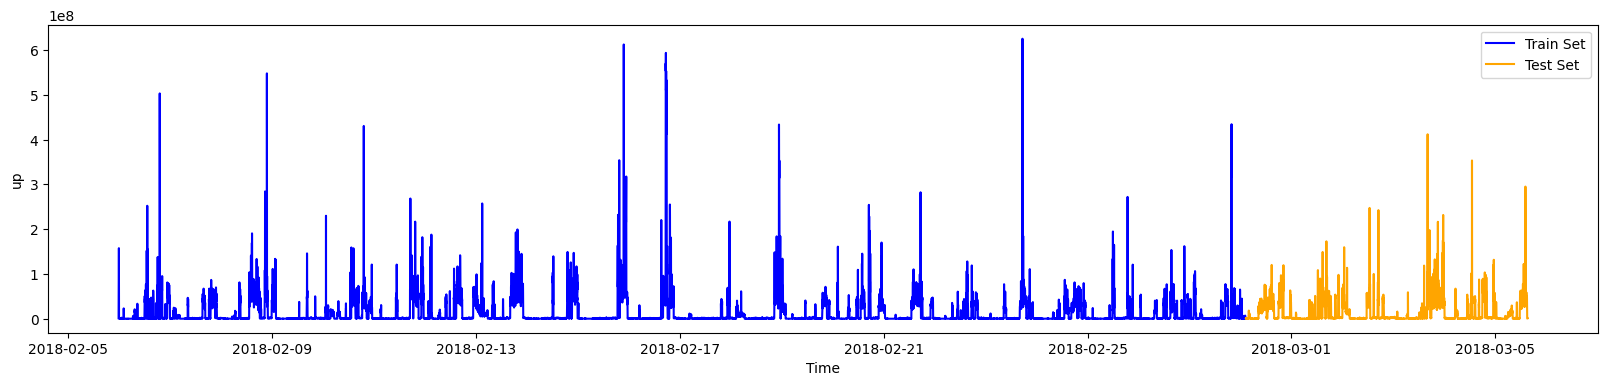

In [ ]:
print("===== DownLink and UpLink for elborn station in Spain =====")
plot(train_poblesec, test_poblesec, 'down')
plot(train_poblesec, test_poblesec, 'up')

===== DownLink and UpLink for Elborn station in Spain =====


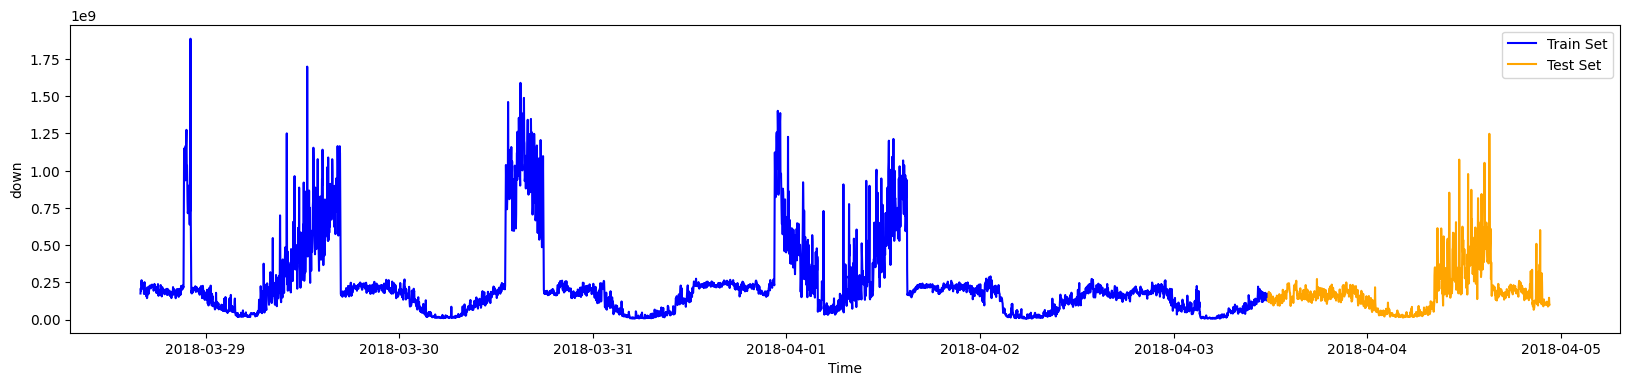

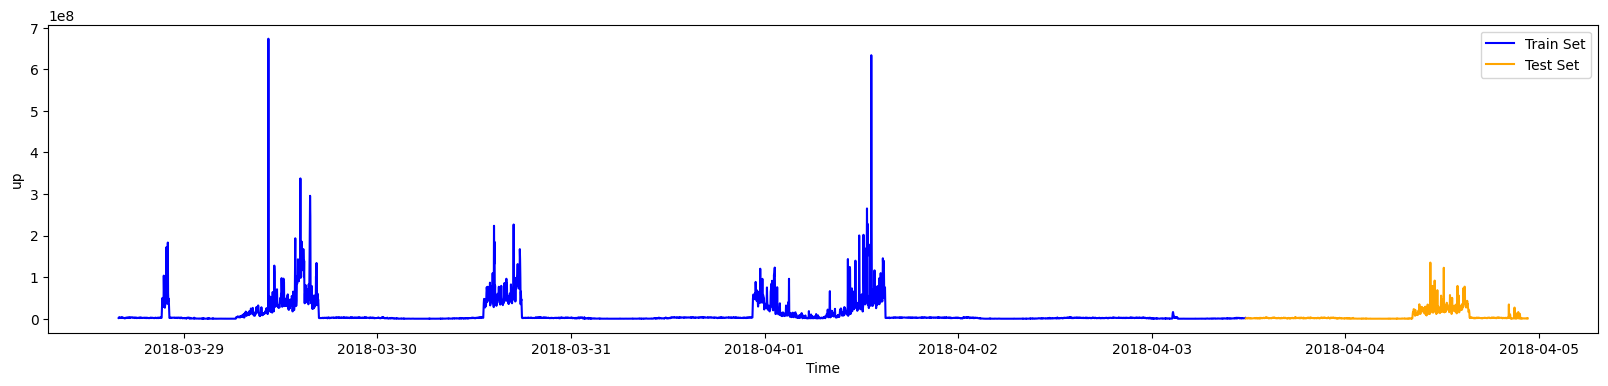

In [ ]:
print("===== DownLink and UpLink for Elborn station in Spain =====")
plot(train_elborn, test_elborn, 'down')
plot(train_elborn, test_elborn, 'up')

===== DownLink and UpLink for LesCorts station in Spain =====


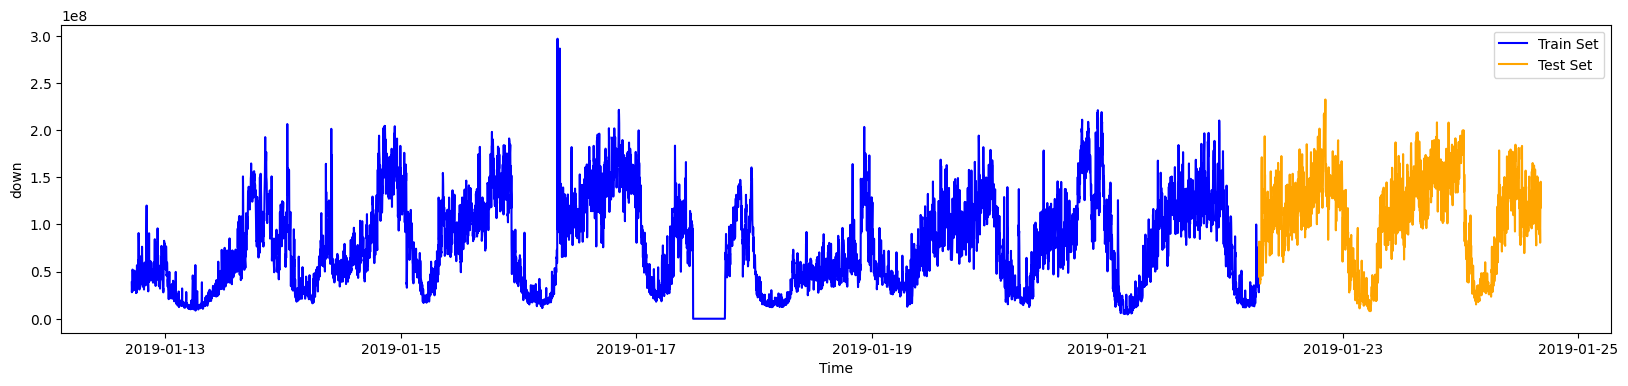

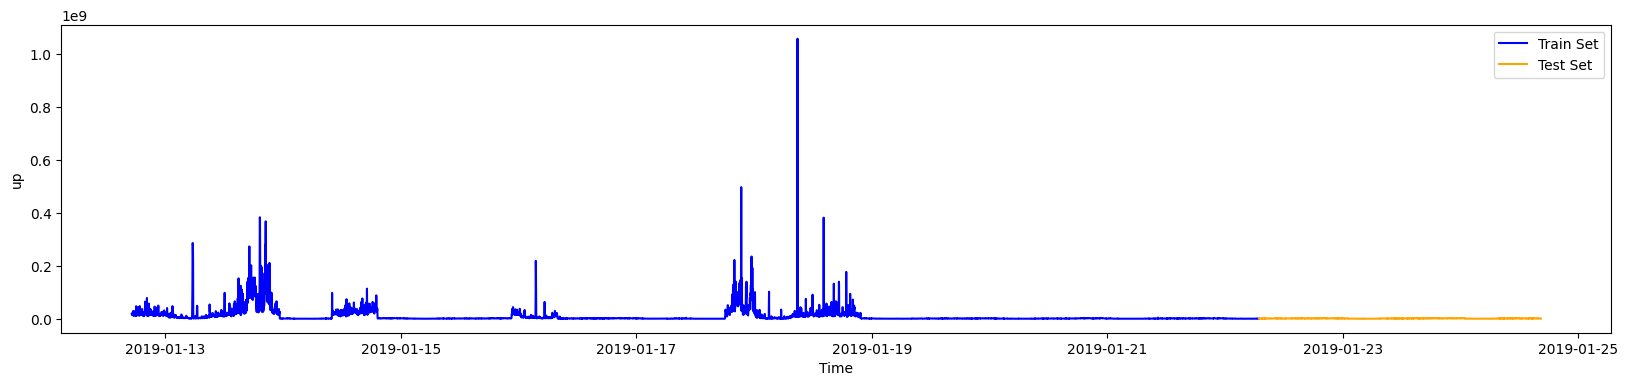

In [ ]:
print("===== DownLink and UpLink for LesCorts station in Spain =====")
plot(train_lescorts, test_lescorts, 'down')
plot(train_lescorts, test_lescorts, 'up')

## Seasonality Check



In [ ]:
def plot_hourly_traffic(df, figsize=(15, 7)):
    # Extract hour and calculate hourly averages
    df = df.copy()
    if 'hour' not in df.columns:
        df['hour'] = df.index.hour
    
    hourly_stats = df.groupby(['hour']).mean()
    
    # Convert to megabits for readability if values are large
    scale_factor = 1_000_000  # Assuming original values are in bytes
    y_label = 'Bitrate (Mbps)'
    
    if hourly_stats['down'].mean() > 1_000_000:
        hourly_stats['down'] = hourly_stats['down'] / scale_factor
        hourly_stats['up'] = hourly_stats['up'] / scale_factor
    
    # Ensure all hours (0-23) are included
    all_hours = pd.DataFrame(index=range(24))
    hourly_stats = hourly_stats.join(all_hours, how='right')
    hourly_stats = hourly_stats.fillna(0)
    
    # Create the plot
    plt.figure(figsize=figsize)
    
    # Plot with enhanced styling
    plt.plot(hourly_stats.index, hourly_stats['down'], 'o-', 
             linewidth=2.5, markersize=8, color='#1f77b4', label='Downlink')
    plt.plot(hourly_stats.index, hourly_stats['up'], 's-', 
             linewidth=2.5, markersize=8, color='#ff7f0e', label='Uplink')
    
    # Set x-axis ticks to show all hours
    plt.xticks(range(24), [f'{h:02d}:00' for h in range(24)], rotation=45)
    
    # Add grid for better readability
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # Enhance the plot with better labels and title
    plt.title('Network Traffic by Hour of Day', fontsize=18, fontweight='bold', pad=20)
    plt.xlabel('Hour of Day', fontsize=14, labelpad=10)
    plt.ylabel(y_label, fontsize=14, labelpad=10)
    
    # Format legend
    plt.legend(loc='upper left', fontsize=12, frameon=True, facecolor='white', edgecolor='gray')
    
    # Add annotations for peak hours
    down_peak_hour = hourly_stats['down'].idxmax()
    down_peak_value = hourly_stats['down'].max()
    up_peak_hour = hourly_stats['up'].idxmax()
    up_peak_value = hourly_stats['up'].max()
    
    plt.annotate(f'Peak: {down_peak_value:.2f}',
                xy=(down_peak_hour, down_peak_value),
                xytext=(5, 10), textcoords='offset points',
                arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0.2'))
    
    plt.annotate(f'Peak: {up_peak_value:.2f}',
                xy=(up_peak_hour, up_peak_value),
                xytext=(5, 10), textcoords='offset points',
                arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0.2'))
    
    # Improve the layout
    plt.tight_layout()
    # Return the plot for further customization if needed
    return plt

def check_seasonality(df):
    if 'hour' not in df.columns:
        df['hour'] = df.index.hour
    hourly_stats = df.groupby(['hour']).mean()
    return hourly_stats


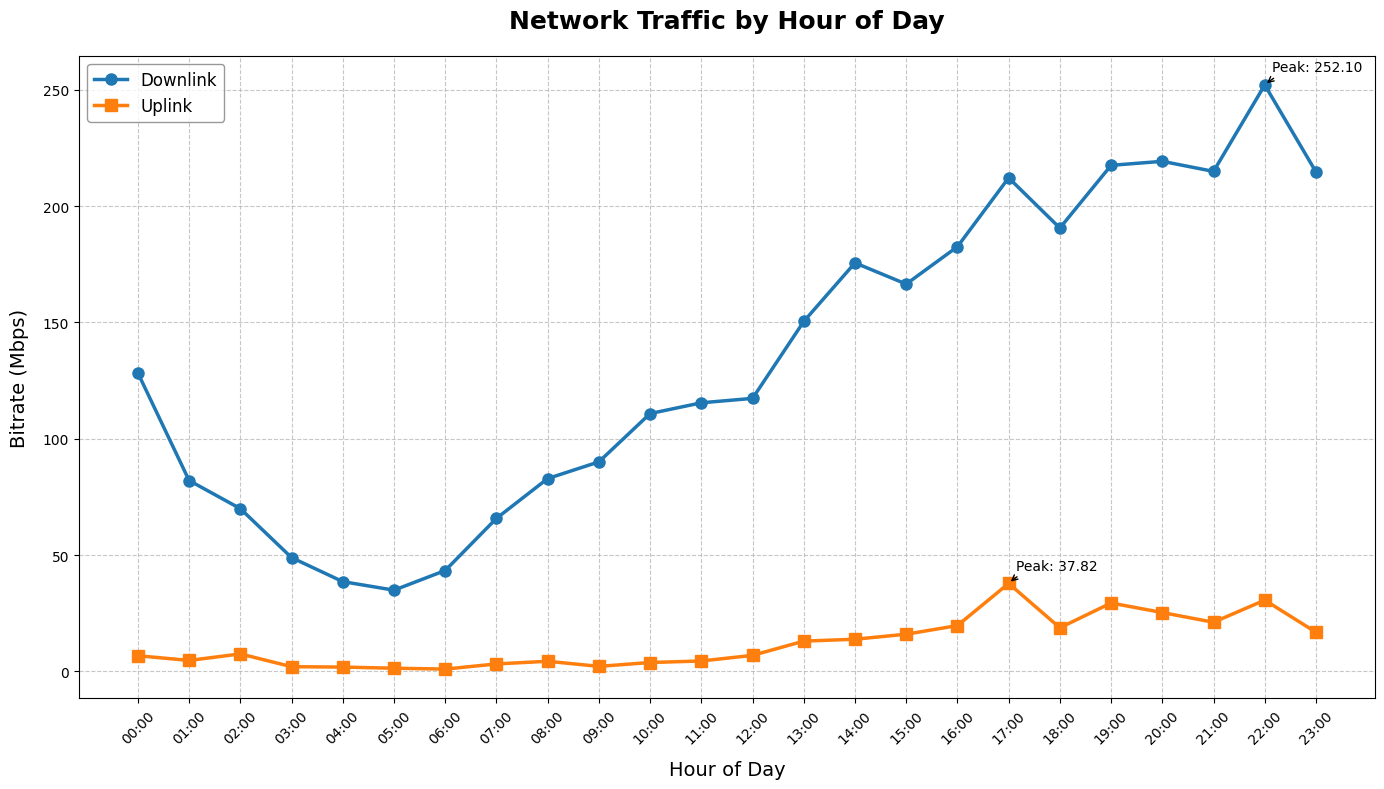

In [ ]:
hour_stats = check_seasonality(train_poblesec)
plot = plot_hourly_traffic(train_poblesec)

# Save the figure (optional)
plt.savefig('hourly_network_traffic_poblesec.png', dpi=300, bbox_inches='tight')

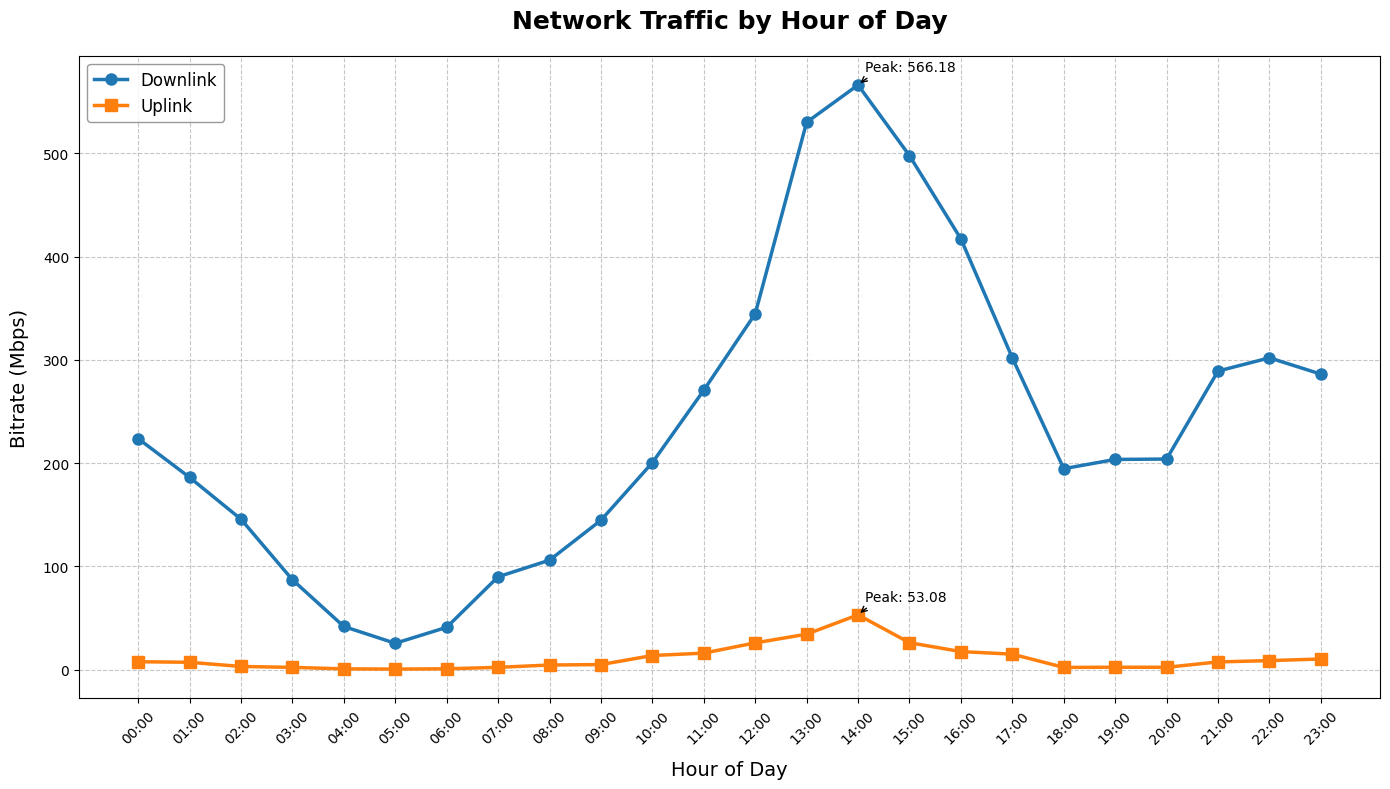

In [ ]:
hour_stats = check_seasonality(train_elborn)
plot = plot_hourly_traffic(train_elborn)

# Save the figure (optional)
plt.savefig('hourly_network_traffic_elborn.png', dpi=300, bbox_inches='tight')

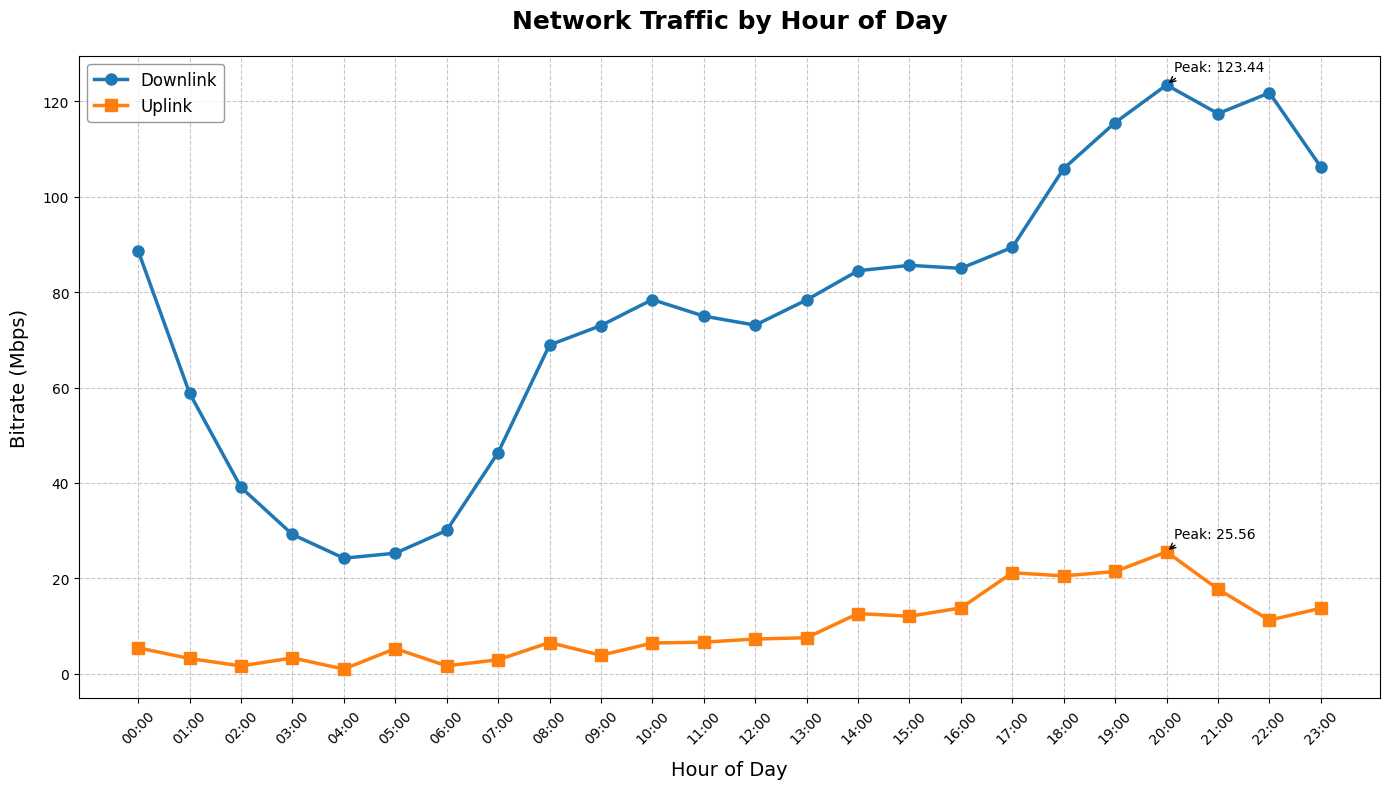

In [ ]:
hour_stats = check_seasonality(train_lescorts)
plot = plot_hourly_traffic(train_lescorts)

# Save the figure (optional)
plt.savefig('hourly_network_traffic_lescorts.png', dpi=300, bbox_inches='tight')

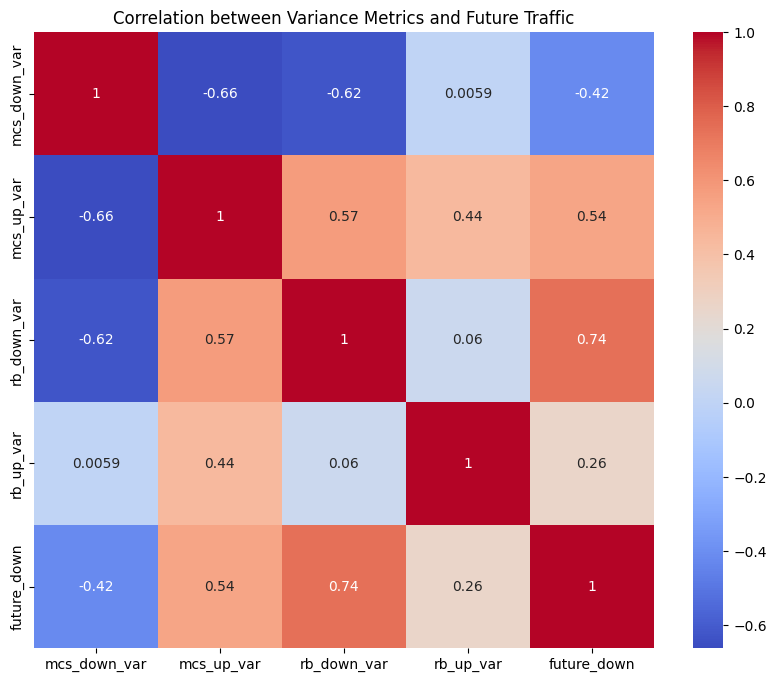

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Shift target column to align current variances with future traffic
df_shifted = train_poblesec.copy()
df_shifted['future_down'] = df_shifted['down'].shift(-1)  # Next interval's traffic

# Calculate correlations
corr = df_shifted[['mcs_down_var', 'mcs_up_var', 'rb_down_var', 'rb_up_var', 'future_down']].corr()

# Visualize
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation between Variance Metrics and Future Traffic')
plt.show()